# 511 regional transit feed (GTFS) for Bay Area airports

**Tasks covered here:**
1. **Download** the 511 regional transit schedule (GTFS) with a 511 API key.
2. **Confirm** the feed works for SFO, OAK and SJC: it is a valid GTFS file, it has a weekday with service, and it has transit stops at all three airports.
3. **Test route:** one transit trip from a single tract (Downtown Berkeley) to SFO using this feed.

**Before running:**
- Get a free 511 token at <https://511.org/open-data/token> and set it in the terminal you start Jupyter from: `export KEY_511=your_token`. The token is read from the environment so it never gets saved in the notebook.
- The test route needs the OpenStreetMap file from `osm_network.ipynb` (Geofabrik Northern California extract) at `data/raw/norcal-latest.osm.pbf`. Use the full extract, not the drive-only filtered one: the route needs footpaths for walking to and from stops.
- Routing uses [r5py](https://r5py.readthedocs.io), which needs **Java 21**. If you have several Java versions, run `export JAVA_HOME=$(/usr/libexec/java_home -v 21)` (macOS) before starting Jupyter.
- Install the packages: `pip install -r requirements.txt`.

## Setup

In [1]:
import datetime
import os
import warnings
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import r5py
import requests
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src.config import AIRPORTS, COUNTY_FIPS, CRS, OUTPUT_DIR, PROCESSED_DIR, RAW_DIR, cleaning_log, log_step
from src.lodes import load_airports

# transit stops this close to an airport polygon count as airport stops
AIRPORT_STOP_RADIUS_M = 500

GTFS_PATH = f"{RAW_DIR}/511_regional_gtfs.zip"
OSM_PATH = f"{RAW_DIR}/norcal-latest.osm.pbf"  # made by osm_network.ipynb

# both explained in section 3: we route one departure minute on purpose, and R5's blank stop_name complaints are expected
warnings.filterwarnings("ignore", message="The provided departure time window is below 5 minutes")
warnings.filterwarnings("ignore", message="R5 reported the following issues with GTFS file")

## 1. Download the 511 regional feed
511 publishes one GTFS feed covering every Bay Area transit agency (operator `RG`, "regional"). The API allows 60 requests an hour, so we download it once to `data/raw/` (not committed to GitHub) and reuse the file.

In [2]:
if not os.path.exists(GTFS_PATH):
    key = os.environ.get("KEY_511")
    if not key:
        raise ValueError("Set your 511 token first: export KEY_511=your_token (free at https://511.org/open-data/token)")
    response = requests.get(f"https://api.511.org/transit/datafeeds?api_key={key}&operator_id=RG", stream=True)
    # requests' own error message includes the url, which contains the token, so report only the status and reply
    if response.status_code != 200:
        raise ValueError(f"511 request failed with status {response.status_code}: {response.text[:200]}")
    with open(GTFS_PATH, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            file.write(chunk)

print(f"GTFS feed: {os.path.getsize(GTFS_PATH) / 1e6:.0f} MB, downloaded {datetime.date.fromtimestamp(os.path.getmtime(GTFS_PATH))}")

GTFS feed: 57 MB, downloaded 2026-10-27


## 2. Confirm the feed works

### 2.1 Check the file
If the token is wrong, 511 sends back a short error message instead of a zip file. We check the download is a real GTFS zip with the tables we need.

In [3]:
if not zipfile.is_zipfile(GTFS_PATH):
    with open(GTFS_PATH, errors="replace") as file:
        start = file.read(200)
    raise ValueError(f"{GTFS_PATH} is not a zip file, so it is probably an error message. Delete it and try again. It starts with: {start}")

with zipfile.ZipFile(GTFS_PATH) as feed:
    files = feed.namelist()
needed = ["stops.txt", "routes.txt", "trips.txt", "stop_times.txt", "calendar.txt", "calendar_dates.txt"]
missing = [name for name in needed if name not in files]
if missing:
    raise ValueError(f"The feed is missing {missing}")
print(f"Feed OK: {len(files)} files, including all of {needed}")


def read_gtfs(name, **kwargs):
    """Read one table from the feed, with every column as text so IDs keep their leading zeros."""
    with zipfile.ZipFile(GTFS_PATH) as feed, feed.open(name) as file:
        return pd.read_csv(file, dtype=str, **kwargs)

Feed OK: 27 files, including all of ['stops.txt', 'routes.txt', 'trips.txt', 'stop_times.txt', 'calendar.txt', 'calendar_dates.txt']


### 2.2 Pick a weekday with service
GTFS says which days each trip runs: `calendar.txt` gives the weekly pattern and date range, and `calendar_dates.txt` adds or removes single dates (holidays). The test route runs on one typical weekday: the first Wednesday on or after the feed was downloaded that has service.

In [4]:
calendar = read_gtfs("calendar.txt")
calendar_dates = read_gtfs("calendar_dates.txt")
trips = read_gtfs("trips.txt", usecols=["route_id", "service_id", "trip_id"])
trips = trips.merge(read_gtfs("routes.txt", usecols=["route_id", "agency_id"]), on="route_id")


def services_on(date):
    """service_ids running on a date: the weekly calendar, plus added (1) and minus removed (2) dates."""
    day = date.strftime("%Y%m%d")
    weekday = date.strftime("%A").lower()
    running = (calendar[weekday] == "1") & (calendar["start_date"] <= day) & (calendar["end_date"] >= day)
    services = set(calendar.loc[running, "service_id"])
    exceptions = calendar_dates[calendar_dates["date"] == day]
    services |= set(exceptions.loc[exceptions["exception_type"] == "1", "service_id"])
    services -= set(exceptions.loc[exceptions["exception_type"] == "2", "service_id"])
    return services


last_day = datetime.datetime.strptime(calendar["end_date"].max(), "%Y%m%d").date()
SERVICE_DATE = datetime.date.fromtimestamp(os.path.getmtime(GTFS_PATH))
SERVICE_DATE += datetime.timedelta(days=(2 - SERVICE_DATE.weekday()) % 7)  # weekday 2 is Wednesday
while not trips["service_id"].isin(services_on(SERVICE_DATE)).any():
    SERVICE_DATE += datetime.timedelta(days=7)
    if SERVICE_DATE > last_day:
        raise ValueError("No Wednesday with service left in this feed; download a newer one")

day_trips = trips[trips["service_id"].isin(services_on(SERVICE_DATE))]
log_step("gtfs_trips", f"runs on {SERVICE_DATE}", len(trips), len(day_trips), "trip does not run on the service date")
print(f"Service date: {SERVICE_DATE:%A %B %d, %Y}, with {day_trips['agency_id'].nunique()} of {trips['agency_id'].nunique()} agencies running")

[gtfs_trips] runs on 2026-10-28: 87,764 -> 29,328 (trip does not run on the service date)
Service date: Wednesday October 28, 2026, with 41 of 41 agencies running


### 2.3 Transit stops at each airport
A stop counts as an airport stop if it is within 500 m of the airport's TIGER polygon (the same landmarks file `data_processing.ipynb` uses). We keep only stops you can board at (`location_type` 0); stations and entrances are just groupings of those. Read the printed list: it is the easiest place to spot a stop that does not belong.

In [5]:
airports = load_airports().to_crs(CRS)
stops = read_gtfs("stops.txt", usecols=["stop_id", "stop_name", "stop_lat", "stop_lon", "location_type"])
stops = stops[stops["location_type"].fillna("0") == "0"]
stops = gpd.GeoDataFrame(
    stops[["stop_id", "stop_name"]],
    geometry=gpd.points_from_xy(stops["stop_lon"].astype(float), stops["stop_lat"].astype(float)),
    crs=4326,
).to_crs(CRS)

near_airports = airports.copy()
near_airports["geometry"] = airports.buffer(AIRPORT_STOP_RADIUS_M)
airport_stops = gpd.sjoin(stops, near_airports, predicate="within")[["stop_id", "stop_name", "code", "geometry"]]
log_step("gtfs_stops", f"within {AIRPORT_STOP_RADIUS_M} m of an airport", len(stops), len(airport_stops), "stop not near SFO, OAK or SJC")

for code in AIRPORTS:
    found = airport_stops[airport_stops["code"] == code]
    if found.empty:
        raise ValueError(f"No stops found near {code}")
    print(f"{code} ({len(found)} stops): {'; '.join(sorted(set(found['stop_name'])))}\n")

[airports] match airport names: 8,110 -> 3 (TIGER landmark is not an SFO, OAK or SJC airport (k2457))
[gtfs_stops] within 500 m of an airport: 19,802 -> 93 (stop not near SFO, OAK or SJC)
SFO (52 stops): 1800 Old Bayshore Hwy (PM); 3rd Ave & Belle Air School; 585 McDonnell Rd-UAL Cargo; 586 McDonnell Rd-Opposite UAL Cargo; Bayshore Hwy & Mitten Rd; Garage A; Garage G and BART; Grand Hyatt at SFO; International Terminal Courtyard A Bus Stop; International Terminal Upper Level Bus Stop; International Terminal and A Gates; International Terminal and G Gates; Long Term Parking; Lot D Bus Stop 11; Lot D Bus Stop 12; Lot D Bus Stop 13; Lot D Bus Stop 14; Lot D Bus Stop 15; McDonnell Rd & West Area Rd; McDonnell Rd & West Field Rd; Northbound N. McDonnell Rd. Bus Stop; Rental Car Center; S Airport Blvd & Airport Long Term Parking; S Airport Blvd & Belle Air Rd; S Airport Blvd & UAL Maintenance-Gate 78; SFO Airport Terminal 2-Lower Level; SFO Airport Terminal 3-Lower Level; SFO Airport Termina

### 2.4 Save the cleaning log
The row counts from each step above, saved next to the log from `data_processing.ipynb`.

In [6]:
pd.DataFrame(cleaning_log).to_csv(f"{OUTPUT_DIR}/transit_cleaning_log.csv", index=False)
pd.DataFrame(cleaning_log)

,dataset,step,rows_before,rows_after,reason
0,gtfs_trips,runs on 2026-10-28,87764,29328,trip does not run on the service date
1,airports,match airport names,8110,3,"TIGER landmark is not an SFO, OAK or SJC airpo..."
2,gtfs_stops,within 500 m of an airport,19802,93,"stop not near SFO, OAK or SJC"


## 3. Test route: Downtown Berkeley to SFO
One transit trip we can check by hand. The origin is the population-weighted centroid (from `data_processing.ipynb`) of the tract containing Downtown Berkeley BART, `06001422902`. In the feed's timetable, a Red line train leaves Downtown Berkeley at 12:24 and reaches SFO at 13:22 (58 min, no transfer). So leaving home at 12:15, the trip should take a little over an hour: the walk to the station, the wait for the 12:24 train, and the 58-minute ride.

R5 (inside r5py) builds a routing network from the OpenStreetMap streets and the feed, which takes a few minutes. `allow_errors=True` is needed because the 511 feed leaves `stop_name` blank on pathway nodes inside stations, which GTFS allows but R5 rejects. We route a single departure minute (12:15) so the result matches the timetable check exactly.

In [7]:
if not os.path.exists(OSM_PATH):
    raise ValueError(f"{OSM_PATH} not found: run osm_network.ipynb first (or get the Geofabrik Northern California extract from Matt)")

TEST_TRACT = "06001422902"
DEPARTURE = datetime.datetime.combine(SERVICE_DATE, datetime.time(12, 15))

network = r5py.TransportNetwork(OSM_PATH, [GTFS_PATH], allow_errors=True)
centroids = gpd.read_file(f"{PROCESSED_DIR}/tract_centroids_4326.gpkg")
origin = centroids[centroids["GEOID"] == TEST_TRACT].rename(columns={"GEOID": "id"})[["id", "geometry"]]
sfo_stops = airport_stops[airport_stops["code"] == "SFO"].to_crs(4326)
destinations = sfo_stops.rename(columns={"stop_id": "id"})[["id", "geometry"]].drop_duplicates("id")

times = r5py.TravelTimeMatrix(
    network,
    origins=origin,
    destinations=destinations,
    departure=DEPARTURE,
    departure_time_window=datetime.timedelta(minutes=1),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    snap_to_network=True,
)
fastest = times.dropna(subset=["travel_time"]).sort_values("travel_time").iloc[0]
stop_name = sfo_stops.loc[sfo_stops["stop_id"] == fastest["to_id"], "stop_name"].iloc[0]
print(f"Tract {TEST_TRACT} -> SFO, leaving {DEPARTURE:%H:%M} on {SERVICE_DATE:%a %Y-%m-%d}: "
      f"{fastest['travel_time']:.0f} min door to door, to {stop_name}")

Tract 06001422902 -> SFO, leaving 12:15 on Wed 2026-10-28: 67 min door to door, to Garage G and BART


### 3.1 Map of the test route
r5py can also return the turn-by-turn route (`DetailedItineraries`), but on the full regional feed it runs out of memory even with 10 GB, so we rebuild the trip from the timetable instead. We take every stop within 1 km of the tract centroid. A trip there counts if it leaves after you could walk to it (straight-line distance at 1 m/s, from 12:15) and later stops at an SFO stop. We keep the one that reaches SFO first. If its arrival matches R5's 67 minutes, the map shows the same trip R5 found. The walk to the first stop is drawn as a straight dashed line, not the actual street path.

In [8]:
from shapely.geometry import LineString
from shapely.ops import substring

from src.lodes import download

WALK_RADIUS_M = 1000
WALK_SPEED_M_PER_S = 1.0  # r5py's default walking speed (3.6 km/h)

home = origin.to_crs(CRS).geometry.iloc[0]
nearby = stops[stops.distance(home) <= WALK_RADIUS_M]
sfo_ids = set(sfo_stops["stop_id"])

# stop_times is about 200 MB, so read it in pieces and keep only stops near home or at SFO
keep = []
with zipfile.ZipFile(GTFS_PATH) as feed, feed.open("stop_times.txt") as file:
    columns = ["trip_id", "stop_id", "stop_sequence", "arrival_time", "departure_time"]
    for chunk in pd.read_csv(file, dtype=str, usecols=columns, chunksize=1_000_000):
        keep.append(chunk[chunk["trip_id"].isin(day_trips["trip_id"]) & chunk["stop_id"].isin(set(nearby["stop_id"]) | sfo_ids)])
keep = pd.concat(keep).dropna(subset=["departure_time"])
keep["seconds"] = keep["departure_time"].str.split(":", expand=True).astype(int).pipe(lambda t: t[0] * 3600 + t[1] * 60 + t[2])
keep["stop_sequence"] = keep["stop_sequence"].astype(int)

walk_seconds = nearby.set_index("stop_id").distance(home) / WALK_SPEED_M_PER_S
start_seconds = DEPARTURE.hour * 3600 + DEPARTURE.minute * 60
board = keep[keep["stop_id"].isin(nearby["stop_id"])]
board = board[board["seconds"] >= start_seconds + board["stop_id"].map(walk_seconds)]
alight = keep[keep["stop_id"].isin(sfo_ids)]
options = board.merge(alight, on="trip_id", suffixes=("_board", "_alight"))
options = options[options["stop_sequence_alight"] > options["stop_sequence_board"]]
trip = options.sort_values(["seconds_alight", "seconds_board"], ascending=[True, False]).iloc[0]

# check the timetable trip arrives when R5 says
r5_arrival = DEPARTURE + datetime.timedelta(minutes=float(fastest["travel_time"]))
print(f"Timetable: board {trip['departure_time_board'][:5]}, arrive {trip['departure_time_alight'][:5]}.  R5: arrive {r5_arrival:%H:%M}")

# the trip's track between the two stops, from shapes.txt
trip_info = read_gtfs("trips.txt", usecols=["trip_id", "route_id", "shape_id"]).set_index("trip_id").loc[trip["trip_id"]]
route_info = read_gtfs("routes.txt").set_index("route_id").loc[trip_info["route_id"]]
route_label = route_info["route_long_name"] if pd.notna(route_info.get("route_long_name")) else route_info["route_short_name"]
shape = read_gtfs("shapes.txt")
shape = shape[shape["shape_id"] == trip_info["shape_id"]].sort_values("shape_pt_sequence", key=lambda seq: seq.astype(int))
track = gpd.GeoSeries(gpd.points_from_xy(shape["shape_pt_lon"].astype(float), shape["shape_pt_lat"].astype(float)), crs=4326).to_crs(CRS)
track = LineString(track.tolist())
board_stop = stops.set_index("stop_id").loc[trip["stop_id_board"]]
alight_stop = stops.set_index("stop_id").loc[trip["stop_id_alight"]]
ride = substring(track, track.project(board_stop.geometry), track.project(alight_stop.geometry))
walk = LineString([home, board_stop.geometry])
print(f"{route_label}: {board_stop['stop_name']} -> {alight_stop['stop_name']}, {ride.length / 1000:.1f} km by transit, {walk.length:.0f} m walk")

Timetable: board 12:24, arrive 13:22.  R5: arrive 13:22


Richmond to SF Int'l Airport SFO/Millbrae: Downtown Berkeley -> San Francisco International Airport, 45.4 km by transit, 207 m walk


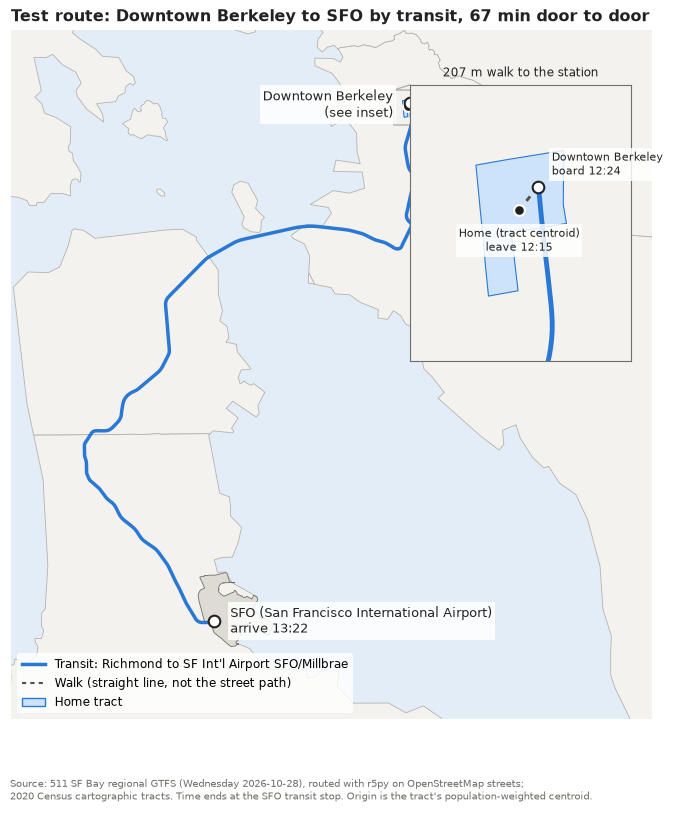

In [9]:
# Census cartographic tracts are clipped to the shoreline, so the Bay shows as water (the TIGER tracts extend into it)
download("https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_06_tract_500k.zip", f"{RAW_DIR}/ca_tracts_2020_cartographic.zip")
tracts = gpd.read_file(f"{RAW_DIR}/ca_tracts_2020_cartographic.zip")
tracts = tracts[tracts["COUNTYFP"].isin(COUNTY_FIPS)].to_crs(CRS)
counties = tracts.dissolve("COUNTYFP")
home_tract = tracts[tracts["GEOID"] == TEST_TRACT]
sfo = airports[airports["code"] == "SFO"]

transit_color, walk_color, ink, muted = "#2a78d6", "#52514e", "#222222", "#6f6e69"
water, land, borders = "#e3edf7", "#f3f2ee", "#b5b3ab"
label = dict(fontsize=9, color=ink, zorder=6, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))


def draw(ax, line_scale=1.0):
    # the base map and the route; used for the main map and the zoomed inset
    ax.set_facecolor(water)
    counties.plot(ax=ax, color=land, edgecolor=borders, linewidth=0.6)
    sfo.plot(ax=ax, color="#dddbd3", edgecolor=muted, linewidth=0.6)
    home_tract.plot(ax=ax, color="#cde2fb", edgecolor=transit_color, linewidth=0.8)
    gpd.GeoSeries([ride], crs=CRS).plot(ax=ax, color=transit_color, linewidth=2.5 * line_scale, zorder=3)
    gpd.GeoSeries([walk], crs=CRS).plot(ax=ax, color=walk_color, linewidth=1.5 * line_scale, linestyle=(0, (2, 2)), zorder=3)
    ax.scatter(home.x, home.y, s=60, color=ink, edgecolor="white", linewidth=1.5, zorder=5)
    for stop in (board_stop, alight_stop):
        ax.scatter(stop.geometry.x, stop.geometry.y, s=70, color="white", edgecolor=ink, linewidth=1.5, zorder=5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")


fig, ax = plt.subplots(figsize=(7, 8.5))
draw(ax)
ax.annotate(f"SFO ({alight_stop['stop_name']})\narrive {trip['departure_time_alight'][:5]}", (alight_stop.geometry.x, alight_stop.geometry.y), xytext=(12, -8), textcoords="offset points", **label)
ax.annotate("Downtown Berkeley\n(see inset)", (board_stop.geometry.x, board_stop.geometry.y), xytext=(-12, -10), textcoords="offset points", ha="right", **label)
xmin, ymin, xmax, ymax = gpd.GeoSeries([ride, walk, sfo.geometry.iloc[0]], crs=CRS).total_bounds
pad = 4000
ax.set_xlim(xmin - pad, xmax + pad + 9000)  # room on the right for the inset
ax.set_ylim(ymin - pad, ymax + pad)
for side in ax.spines.values():
    side.set_visible(False)

# zoomed inset: the walk from the home tract to the station
inset = ax.inset_axes([0.6, 0.52, 0.39, 0.4])
draw(inset, line_scale=1.4)
x0, y0, x1, y1 = gpd.GeoSeries([walk, home_tract.geometry.iloc[0]], crs=CRS).total_bounds
inset_pad = 450
inset.set_xlim(x0 - inset_pad, x1 + inset_pad)
inset.set_ylim(y0 - inset_pad, y1 + inset_pad)
for side in inset.spines.values():
    side.set_edgecolor(muted)
ax.indicate_inset_zoom(inset, edgecolor=muted)
inset.annotate(f"Home (tract centroid)\nleave {DEPARTURE:%H:%M}", (home.x, home.y), xytext=(0, -12), textcoords="offset points", ha="center", va="top", **{**label, "fontsize": 8})
inset.annotate(f"{board_stop['stop_name']}\nboard {trip['departure_time_board'][:5]}", (board_stop.geometry.x, board_stop.geometry.y), xytext=(10, 6), textcoords="offset points", va="bottom", **{**label, "fontsize": 8})
inset.set_title(f"{walk.length:.0f} m walk to the station", fontsize=8.5, color=ink)

ax.legend(handles=[
    Line2D([], [], color=transit_color, linewidth=2.5, label=f"Transit: {route_label}"),
    Line2D([], [], color=walk_color, linewidth=1.5, linestyle=(0, (2, 2)), label="Walk (straight line, not the street path)"),
    Patch(facecolor="#cde2fb", edgecolor=transit_color, label="Home tract"),
], loc="lower left", fontsize=8.5, frameon=True, facecolor="white", edgecolor="none")
ax.set_title(f"Test route: Downtown Berkeley to SFO by transit, {fastest['travel_time']:.0f} min door to door",
             fontsize=11.5, fontweight="bold", color=ink, loc="left")
fig.text(0.02, 0.02, f"Source: 511 SF Bay regional GTFS ({SERVICE_DATE:%A %Y-%m-%d}), routed with r5py on OpenStreetMap streets;\n"
         "2020 Census cartographic tracts. Time ends at the SFO transit stop. Origin is the tract's population-weighted centroid.",
         fontsize=7.5, color=muted)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(f"{OUTPUT_DIR}/test_route_berkeley_sfo.png", dpi=300)

## Limitations
- **The test route ends at the airport transit stop.** The walk or shuttle from the stop to a terminal or workplace is not included.
- **Airport stops come from a simple distance rule.** The SJC polygon is large enough that the 500 m rule includes Santa Clara Caltrain, Santa Clara Transit Center and some Coleman Ave stops, 1.5–2 km from the terminals. Check the list in section 2.3.
- **One weekday.** The test route uses a single Wednesday; weekend and holiday service is thinner.
- **After-midnight trips.** GTFS stores a late-night trip on the day it started (25:30 means 1:30 am the next day), and R5 only runs trips from the day it routes on. This does not affect the midday test route, but routing early-morning shifts will need the previous night's trips copied onto the service date.